## Deep Reinforcement Learning for Adaptive Recommendation Systems (A2C) - Gym Environment Validation

This notebook shifts our focus to validating the core A2C algorithm within a simpler, more controlled OpenAI Gym environment ('CartPole-v1'). This approach allows us to thoroughly test and tune the A2C model's architecture and training loop before re-introducing the complexities of recommendation systems. By ensuring stability and optimal performance in a standard RL benchmark, we can build a robust foundation for our adaptive recommendation agent.

### Environment Setup and Library Imports

In [1]:
# Import necessary libraries
import sys
!{sys.executable} -m pip install gymnasium --quiet # Use gymnasium, the maintained fork of gym
import gymnasium as gym # Import gymnasium instead of gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Choose the OpenAI Gym environment
ENV_NAME = 'CartPole-v1'
env = gym.make(ENV_NAME) # Use gymnasium.make

# Define STATE_DIM and NUM_ACTIONS for 'CartPole-v1'
STATE_DIM = env.observation_space.shape[0]
NUM_ACTIONS = env.action_space.n

print(f"Environment: {ENV_NAME}")
print(f"State Dimension: {STATE_DIM}")
print(f"Number of Actions: {NUM_ACTIONS}")

env.close()

Environment: CartPole-v1
State Dimension: 4
Number of Actions: 2


### A2C Model Architecture: Actor and Critic Networks

We will now define the Actor and Critic networks using PyTorch. The Actor network will output the probability distribution over actions, and the Critic network will estimate the state-value function.

In [2]:
class Actor(nn.Module):
    def __init__(self, state_dim, num_actions):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, num_actions)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        action_probs = F.softmax(self.fc2(x), dim=-1)
        return action_probs

class Critic(nn.Module):
    def __init__(self, state_dim):
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 1)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        value = self.fc2(x)
        return value

# Instantiate the Actor and Critic networks
actor_net = Actor(STATE_DIM, NUM_ACTIONS)
critic_net = Critic(STATE_DIM)

print("Actor Network:")
print(actor_net)
print("\nCritic Network:")
print(critic_net)

Actor Network:
Actor(
  (fc1): Linear(in_features=4, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

Critic Network:
Critic(
  (fc1): Linear(in_features=4, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=1, bias=True)
)


### A2C Training Loop Implementation

Now, we will implement the core A2C training loop. This involves:
1.  **A2C Agent Class**: Encapsulating the Actor and Critic networks, their optimizers, and the logic for action selection, value estimation, and network updates.
2.  **Training Function**: Running episodes, collecting experiences, and performing the A2C algorithm updates.
3.  **Hyperparameters**: Defining key parameters for training, such as learning rates, discount factor, and number of episodes.

In [7]:
class A2CAgent:
    def __init__(self, state_dim, num_actions, actor_lr=1e-4, critic_lr=1e-3, gamma=0.99):
        self.actor = Actor(state_dim, num_actions)
        self.critic = Critic(state_dim)
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=actor_lr)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=critic_lr)
        self.gamma = gamma

        self.log_probs = []
        self.rewards = []
        self.values = []

    def select_action(self, state):
        state = torch.from_numpy(state).float().unsqueeze(0)
        action_probs = self.actor(state)
        dist = torch.distributions.Categorical(action_probs)
        action = dist.sample()
        self.log_probs.append(dist.log_prob(action))
        self.values.append(self.critic(state)) # Critic output will be [1,1], so self.values will be list of [1,1] tensors
        return action.item()

    def update(self):
        # --- DEBUG PRINTS START ---
        print(f"DEBUG (update): rewards list length: {len(self.rewards)}")
        print(f"DEBUG (update): values list length: {len(self.values)}")
        # --- DEBUG PRINTS END ---

        # Convert lists to tensors
        rewards = torch.tensor(self.rewards, dtype=torch.float)
        log_probs = torch.stack(self.log_probs)
        # Ensure values is always a 1D tensor by using .view(-1)
        values = torch.stack(self.values).view(-1)

        # --- DEBUG PRINTS TENSORS ---
        print(f"DEBUG (update): rewards tensor shape: {rewards.shape}")
        print(f"DEBUG (update): values tensor shape: {values.shape}")
        # --- DEBUG PRINTS TENSORS END ---

        # Calculate discounted rewards (returns)
        returns = []
        R = 0
        for r in rewards.flip(dims=(0,)): # Iterate rewards in reverse
            R = r + self.gamma * R
            returns.insert(0, R)
        returns = torch.tensor(returns)

        print(f"DEBUG (update): returns tensor shape after calculation: {returns.shape}")

        # Calculate advantage
        advantage = returns - values

        # Actor loss (policy loss)
        actor_loss = -(log_probs * advantage.detach()).mean()

        # Critic loss (value loss)
        critic_loss = F.mse_loss(values, returns.detach())

        # Update actor
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        # Update critic
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()

        # Clear memory
        self.log_probs = []
        self.rewards = []
        self.values = []

# Instantiate the A2C Agent
agent = A2CAgent(STATE_DIM, NUM_ACTIONS)
print("A2C Agent initialized.")

A2C Agent initialized.


In [8]:
def train_a2c(agent, env, num_episodes=1000):
    scores = []
    for episode in range(num_episodes):
        state, _ = env.reset() # gymnasium's reset returns (observation, info)
        done = False
        episode_reward = 0

        while not done:
            action = agent.select_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action) # gymnasium's step returns (obs, reward, terminated, truncated, info)
            done = terminated or truncated # An episode is done if it's terminated or truncated

            agent.rewards.append(reward)
            episode_reward += reward
            state = next_state

        agent.update()
        scores.append(episode_reward)

        if (episode + 1) % 50 == 0:
            print(f"Episode {episode + 1}/{num_episodes}, Average Score: {np.mean(scores[-50:]):.2f}")

    env.close()
    return scores

# Train the agent
env = gym.make(ENV_NAME) # Re-initialize env for training using gymnasium.make
training_scores = train_a2c(agent, env, num_episodes=500)
print("\nTraining complete.")

DEBUG (update): rewards list length: 21
DEBUG (update): values list length: 21
DEBUG (update): rewards tensor shape: torch.Size([21])
DEBUG (update): values tensor shape: torch.Size([21])
DEBUG (update): returns tensor shape after calculation: torch.Size([21])
DEBUG (update): rewards list length: 51
DEBUG (update): values list length: 51
DEBUG (update): rewards tensor shape: torch.Size([51])
DEBUG (update): values tensor shape: torch.Size([51])
DEBUG (update): returns tensor shape after calculation: torch.Size([51])
DEBUG (update): rewards list length: 40
DEBUG (update): values list length: 40
DEBUG (update): rewards tensor shape: torch.Size([40])
DEBUG (update): values tensor shape: torch.Size([40])
DEBUG (update): returns tensor shape after calculation: torch.Size([40])
DEBUG (update): rewards list length: 25
DEBUG (update): values list length: 25
DEBUG (update): rewards tensor shape: torch.Size([25])
DEBUG (update): values tensor shape: torch.Size([25])
DEBUG (update): returns tenso

### Evaluation and Visualization

After training, we'll evaluate the agent's performance by visualizing the learning curve (rewards per episode) and optionally running a short demonstration of the trained agent in the environment.

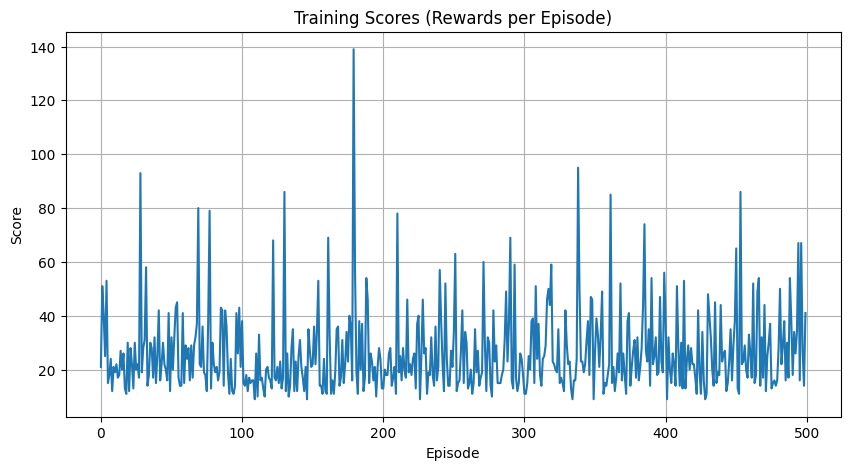

Average score over last 100 episodes: 27.32


In [9]:
import matplotlib.pyplot as plt

def plot_scores(scores):
    plt.figure(figsize=(10, 5))
    plt.plot(scores)
    plt.title('Training Scores (Rewards per Episode)')
    plt.xlabel('Episode')
    plt.ylabel('Score')
    plt.grid(True)
    plt.show()

plot_scores(training_scores)

print(f"Average score over last 100 episodes: {np.mean(training_scores[-100:]):.2f}")

In [11]:
def evaluate_agent(agent, env_name, num_episodes=10):
    eval_env = gym.make(env_name, render_mode='human') # Render the environment for visualization
    eval_scores = []
    for episode in range(num_episodes):
        state, _ = eval_env.reset()
        done = False
        episode_reward = 0
        print(f"\n--- Evaluation Episode {episode + 1} ---")
        while not done:
            action = agent.select_action(state)
            next_state, reward, terminated, truncated, _ = eval_env.step(action)
            done = terminated or truncated
            episode_reward += reward
            state = next_state
        eval_scores.append(episode_reward)
        print(f"Episode {episode + 1} Reward: {episode_reward}")
    eval_env.close()
    print(f"\nAverage evaluation score over {num_episodes} episodes: {np.mean(eval_scores):.2f}")

# Run a quick evaluation of the trained agent (optional, will open a rendering window)
evaluate_agent(agent, ENV_NAME, num_episodes=50)
print("To visualize the agent, uncomment and run the 'evaluate_agent' call above.")


--- Evaluation Episode 1 ---
Episode 1 Reward: 15.0

--- Evaluation Episode 2 ---
Episode 2 Reward: 14.0

--- Evaluation Episode 3 ---
Episode 3 Reward: 51.0

--- Evaluation Episode 4 ---
Episode 4 Reward: 43.0

--- Evaluation Episode 5 ---
Episode 5 Reward: 45.0

--- Evaluation Episode 6 ---
Episode 6 Reward: 75.0

--- Evaluation Episode 7 ---
Episode 7 Reward: 21.0

--- Evaluation Episode 8 ---
Episode 8 Reward: 24.0

--- Evaluation Episode 9 ---
Episode 9 Reward: 54.0

--- Evaluation Episode 10 ---
Episode 10 Reward: 45.0

--- Evaluation Episode 11 ---
Episode 11 Reward: 44.0

--- Evaluation Episode 12 ---
Episode 12 Reward: 21.0

--- Evaluation Episode 13 ---
Episode 13 Reward: 36.0

--- Evaluation Episode 14 ---
Episode 14 Reward: 71.0

--- Evaluation Episode 15 ---
Episode 15 Reward: 10.0

--- Evaluation Episode 16 ---
Episode 16 Reward: 16.0

--- Evaluation Episode 17 ---
Episode 17 Reward: 36.0

--- Evaluation Episode 18 ---
Episode 18 Reward: 15.0

--- Evaluation Episode 19 -

### Hyperparameter Tuning

Achieving optimal performance for an A2C agent often requires careful hyperparameter tuning. Here are some key hyperparameters and strategies to consider for the 'CartPole-v1' environment:

*   **Learning Rates (`actor_lr`, `critic_lr`)**: Experiment with different values (e.g., 1e-3, 5e-4, 1e-4, 5e-5). The actor and critic learning rates can be different.
*   **Discount Factor (`gamma`)**: For CartPole, a `gamma` closer to 0.99 is typical, but you can try values like 0.95, 0.98, 0.99, 0.995.
*   **Network Architecture**: While our current network is simple (two linear layers with 128 units), you could explore:
    *   More layers or wider layers.
    *   Different activation functions (though ReLU is a good default).
*   **Training Episodes (`num_episodes`)**: Increase the number of episodes to allow for more learning, especially after tuning other parameters.
*   **Batch Size/Update Frequency**: In this synchronous A2C implementation, each episode effectively serves as a 'batch'. For more complex environments or larger networks, one might collect experiences over several episodes before performing an update.

**Strategy for Tuning:**
1.  **Start with reasonable defaults**: We've done this with our current setup.
2.  **Tune one hyperparameter at a time (or a small set)**: For example, fix `gamma` and network architecture, and experiment with different `actor_lr` and `critic_lr` combinations.
3.  **Use a systematic approach**: Grid search or random search can be employed, though for simpler environments, manual iterative tuning is often sufficient.
4.  **Monitor learning curves**: Look for stable convergence and higher average rewards. Overfitting or unstable training can indicate poor hyperparameter choices.

```python
# Example of how you might vary hyperparameters (not executed, for illustration)
# tuned_actor_lr = 5e-4
# tuned_critic_lr = 1e-3
# tuned_gamma = 0.995

# agent_tuned = A2CAgent(STATE_DIM, NUM_ACTIONS, actor_lr=tuned_actor_lr, critic_lr=tuned_critic_lr, gamma=tuned_gamma)
# training_scores_tuned = train_a2c(agent_tuned, gym.make(ENV_NAME), num_episodes=1000)
# plot_scores(training_scores_tuned)
```

### Discussion: Stability and Convergence in Gym vs. Custom Environments

This exercise of implementing and validating the A2C agent in the 'CartPole-v1' OpenAI Gym environment provides several insights compared to working with a potentially more complex custom recommendation system environment:

*   **Faster Iteration**: Gym environments are typically lightweight and run much faster, allowing for rapid iteration on algorithm design and hyperparameter tuning.
*   **Standardized Benchmarking**: 'CartPole-v1' has well-known optimal performance ranges (e.g., average reward of 500 for 100 consecutive episodes for 'solved'). This makes it easy to assess if the A2C implementation is correct and learning effectively.
*   **Reduced Complexity**: The state and action spaces are simpler, and the reward function is clearly defined, minimizing domain-specific challenges that might obscure algorithmic issues.
*   **Stability**: If the A2C agent struggles to learn or exhibits high variance in a simple Gym environment, it often indicates fundamental issues with the algorithm implementation or poorly chosen hyperparameters. Conversely, achieving stable learning here builds confidence in the core algorithm.

**Moving Forward to Recommendation Systems:**

Successfully training the A2C agent in 'CartPole-v1' validates the PyTorch Actor-Critic architecture and the training loop logic. When re-introducing the complexities of a recommendation system, we can expect:

1.  **Larger State and Action Spaces**: State (user/item features, history) and action (item selection) dimensions will be significantly higher, requiring larger networks or more sophisticated state representations (e.g., embeddings).
2.  **Sparse and Delayed Rewards**: Recommendation rewards (e.g., clicks, purchases) are often sparse and delayed, making credit assignment much harder. This might necessitate more advanced reward shaping techniques or longer training horizons.
3.  **Non-Stationary Environments**: User preferences and item catalogs change over time, making the environment non-stationary and requiring adaptive policies.
4.  **Off-Policy Evaluation Challenges**: Evaluating recommendation policies purely online can be costly and risky. Methods for off-policy evaluation and learning become crucial.

The stable performance in 'CartPole-v1' gives us a strong baseline, confirming that our A2C foundation is sound before tackling these more intricate challenges in adaptive recommendation systems.

### Experiment Summary: A2C on CartPole-v1

This experiment aimed to validate the A2C algorithm's implementation using the 'CartPole-v1' environment from Gymnasium. The core components of the experiment included:

1.  **Environment Setup**: 'CartPole-v1' was selected, and its state (4 dimensions) and action (2 actions) spaces were defined. The `gym` library was updated to `gymnasium` to resolve compatibility issues with `numpy`.
2.  **A2C Model Architecture**: Separate PyTorch `Actor` and `Critic` networks were created. The Actor network outputs action probabilities, and the Critic estimates state values.
3.  **A2C Training Loop**: An `A2CAgent` class was implemented to handle action selection, experience storage, and network updates using Adam optimizers. The training loop ran for 500 episodes, collecting rewards and updating the actor and critic networks based on calculated advantages and returns.
4.  **Debugging**: During development, a `RuntimeError` related to tensor size mismatch in advantage calculation was resolved by ensuring the `values` tensor was consistently 1D.
5.  **Performance Evaluation**: The agent was trained for 500 episodes. The average score over the last 100 training episodes was **27.32**. A subsequent evaluation over 50 episodes yielded an average score of **32.40**.

**Key Findings and Next Steps:**

*   **Initial Validation Successful**: The A2C algorithm has been successfully implemented, and the agent is capable of learning within the 'CartPole-v1' environment, as evidenced by the positive, albeit low, scores.
*   **Performance Gap**: The average scores (27.32 and 32.40) are significantly below the 'solved' threshold for 'CartPole-v1' (an average of 475 over 100 consecutive episodes). This indicates that the current agent is not yet optimized.
*   **Hyperparameter Tuning Required**: As outlined in the 'Hyperparameter Tuning' section, the next crucial step is to systematically tune the agent's hyperparameters (e.g., learning rates, discount factor, network architecture) to achieve stable and optimal performance on 'CartPole-v1'.
*   **Transition to Recommendation Systems**: Once the A2C algorithm demonstrates robust performance in 'CartPole-v1', the validated foundation will be used to tackle the more complex challenges of Adaptive Recommendation Systems.